[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HernanBustamanteG/lapis26-p3-corrientes/blob/main/notebooks/04_hito4_catalogo.ipynb)

# 04 · Hito 4: el catálogo

**Qué pide el enunciado.** Un conjunto de corrientes con la parametrización (polo, fase, apocentro, $f$), con
corrientes cortas (< media vuelta), largas (~1 vuelta) y de dos vueltas; para cada una: polo inicial, apocentro,
pericentro, excentricidad, longitud (en vueltas), acercamiento mínimo a la LMC y todas las métricas en los cuatro
modelos. Empezar chico (12 polos × 2 sentidos × 2 apocentros) antes de una grilla grande.

**Diseño.**
- *Piloto* (el "empezar chico"): 12 polos de Fibonacci × 2 sentidos × 3 familias = 72 corrientes.
- *Principal*: los 48 polos HEALPix de `nside = 2` (que ya contienen $\hat{\mathbf n}$ y $-\hat{\mathbf n}$, es decir
  los dos sentidos de giro) × 3 familias × 2 fases $\psi \in \{0°, 90°\}$ = 288 corrientes.
- Las tres familias se calibraron en la MW aislada con $t_{\rm start} = 5$ Gyr y $f = 0.5$ (longitud en vueltas):

| $r_{\rm apo}$ (kpc) | $10^7\,M_\odot$ | $5\times10^7$ | $10^8$ |
|---|---|---|---|
| 25 | 1.59 | 1.76 | 1.80 |
| 40 | 1.26 | 1.61 | **1.72 (doble)** |
| 60 | 0.73 | **1.14 (larga)** | 1.57 |
| 100 | **0.30 (corta)** | 1.11 | 1.31 |

- Cada corriente se guarda en su archivo y cada fila en `filas/<id>.json`: si la sesión de Colab se corta, la
  corrida se **retoma** donde quedó.
- Costo medido: 17 a 50 s por progenitor (cuatro modelos); la principal tarda ~1.5 h con 2 núcleos.

El repositorio trae los catálogos ya calculados en `resultados/` (con su procedencia en `resultados/PROCEDENCIA.md`).
Para rehacerlos, poner `CORRER = True` (o usar la terminal: `python -m p3streams.ejecutar grilla --plan principal --correr`).

In [1]:
import os, sys, subprocess
REPO_URL = "https://github.com/HernanBustamanteG/lapis26-p3-corrientes.git"
USAR_DRIVE = True
if "google.colab" in sys.modules:
    RAIZ = "/content/lapis26-p3-corrientes"
    if not os.path.isdir(RAIZ):
        subprocess.run(["git", "clone", "-q", REPO_URL, RAIZ], check=True)
else:
    RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, RAIZ)
os.chdir(RAIZ)
from p3streams import entorno
if entorno.en_colab():
    entorno.preparar_colab(RAIZ, montar_drive=USAR_DRIVE)
entorno.resumen();

Mounted at /content/drive
Python 3.13.18
  numpy       2.2.6
  scipy       1.16.3
  astropy     7.2.3
  gala        1.12.0
  matplotlib  3.10.0
  pandas      2.2.3
  healpy      1.20.1
  galstreams  1.2.1
Salidas en: /content/drive/MyDrive/lapis26_p3/salidas
ffmpeg: /usr/bin/ffmpeg | CPU: 2
Entorno OK


In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
import matplotlib.pyplot as plt
from p3streams import config as C, util as U, estilo as E
E.usar()
SAL = U.carpeta_nueva("04_hito4")          # carpeta nueva de este notebook (nada se pisa)
FUENTE = "notebooks/04_hito4.ipynb, p3streams " + C.VERSION + ", " + U.ahora()
print("Salidas de este notebook:", SAL)

Salidas de este notebook: /content/drive/MyDrive/lapis26_p3/salidas/04_hito4_20261028_134324


In [3]:
CORRER = False           # True: rehacer la grilla (en Colab, ~1.5 h para 'principal'; se puede retomar)
PLAN = "principal"
from p3streams import ejecutar
ejecutar.main(["grilla", "--plan", PLAN, "--simular"])
if CORRER:
    ejecutar.main(["grilla", "--plan", PLAN, "--correr", "--procesos", str(os.cpu_count() or 1)])

Plan principal: 48 polos HEALPix x 3 familias x 2 fases
  corrientes: 288 (hechas 0, por hacer 288); M_LMC = 1.80e+11 Msun
  carpeta: /content/drive/MyDrive/lapis26_p3/salidas/principal_<FECHA>
  disco ~158 MB, memoria < 1 GB por proceso, tiempo ~84 min con 2 procesos
SIMULACION: no se escribio nada. Para correr: --correr


In [4]:
from p3streams import resultados as R, analisis as An, metricas as Me, figuras as F, potenciales as P
PROPIOS = False          # True: usar la corrida propia mas reciente (salidas/) en vez de la incluida en resultados/
DF, ORIGEN = R.cargar("catalogo_principal", propios=PROPIOS)
print("Catalogo: %d corrientes, leido de %s" % (len(DF), ORIGEN))
sis = P.integrar_sistema()          # el mismo sistema MW + LMC (1.8e11 Msun) del catalogo
DF = An.agregar_geometria(DF, sis)
PIL, _ = R.cargar("catalogo_piloto")
print("Piloto: %d corrientes" % len(PIL))

Catalogo: 288 corrientes, leido de /content/lapis26-p3-corrientes/resultados/catalogo_principal.csv
Piloto: 72 corrientes


### Las columnas que pide el hito 4

Una fila por corriente: `polo` (inicial), `apo_kpc`, `peri_kpc`, `ecc`, `longitud_vueltas_<modelo>`,
`dmin_lmc_kpc` (acercamiento mínimo del progenitor a la LMC en el modelo D) y, para cada métrica, parte y modelo,
`<metrica>_<parte>_<modelo>`; además $\Delta M$, $f_{\rm reflex}$ y el término no lineal.

In [5]:
cols = ["id", "familia", "psi_deg", "apo_kpc", "peri_kpc", "ecc", "longitud_vueltas_A", "dmin_lmc_kpc",
        "tilt_polo_deg_todo_A", "tilt_polo_deg_todo_D", "desalineamiento_deg_todo_A", "desalineamiento_deg_todo_D",
        "dpolo_B_todo", "dpolo_C_todo", "dpolo_D_todo", "dpolo_f_reflex_todo"]
print("Columnas en total:", DF.shape[1])
DF[cols].head(8).round(2)

Columnas en total: 337


,id,familia,psi_deg,apo_kpc,peri_kpc,ecc,longitud_vueltas_A,dmin_lmc_kpc,tilt_polo_deg_todo_A,tilt_polo_deg_todo_D,desalineamiento_deg_todo_A,desalineamiento_deg_todo_D,dpolo_B_todo,dpolo_C_todo,dpolo_D_todo,dpolo_f_reflex_todo
0,p00+_corta_f000,corta,0,100.00,26.68,0.58,0.31,108.09,1.92,16.98,0.63,16.00,24.48,6.01,18.77,0.80
1,p00+_corta_f090,corta,90,100.01,26.70,0.58,0.30,78.50,1.94,16.55,0.55,16.03,34.40,10.84,16.88,0.76
2,p00+_doble_f000,doble,0,40.00,11.46,0.55,1.73,37.75,33.25,30.60,5.36,7.29,2.04,6.00,3.48,0.25
3,p00+_doble_f090,doble,90,40.01,11.52,0.55,1.74,36.32,32.92,30.61,5.03,6.13,1.58,2.73,2.91,0.37
4,p00+_larga_f000,larga,0,60.00,16.79,0.56,1.14,46.08,10.76,9.02,1.96,4.81,12.33,9.08,1.78,0.58
5,p00+_larga_f090,larga,90,60.02,16.82,0.56,1.14,52.80,10.60,6.90,2.88,5.16,4.08,20.06,3.73,0.17
6,p01+_corta_f000,corta,0,100.00,26.68,0.58,0.31,94.56,1.92,16.10,0.58,15.60,28.71,8.85,18.02,0.76
7,p01+_corta_f090,corta,90,100.01,26.70,0.58,0.30,103.31,1.94,20.63,2.06,17.96,27.47,7.06,20.92,0.80


In [6]:
RES = DF.groupby("familia")[["longitud_vueltas_A", "longitud_vueltas_D", "peri_kpc", "apo_kpc", "ecc",
                               "dmin_lmc_kpc", "segundos"]].median().round(2)
RES["n"] = DF.groupby("familia").size()
RES.to_csv(os.path.join(SAL, "hito4_resumen_familias.csv"))
RES

,longitud_vueltas_A,longitud_vueltas_D,peri_kpc,apo_kpc,ecc,dmin_lmc_kpc,segundos,n
familia,,,,,,,,
corta,0.30,0.39,26.72,100.00,0.58,111.60,18.20,96
doble,1.74,1.75,11.50,40.00,0.55,42.79,54.35,96
larga,1.13,1.11,16.83,60.01,0.56,38.39,34.60,96


### El piso del modelo A

Lo que miden las métricas en la MW aislada. Las inclinaciones respecto del polo inicial **no** son cero en A: el
disco hace precesar los planos orbitales que no son polares, más cuanto más cerca pasan del centro. Por eso, para
el polo, se usa además el **cambio vectorial del polo respecto del modelo A** (`dpolo_B`, `dpolo_C`, `dpolo_D`),
que no incluye la precesión por el disco (está igual en los cuatro modelos).

In [7]:
PISO = DF.groupby("familia")[["desalineamiento_deg_todo_A", "tilt_polo_deg_todo_A", "tilt_plano_deg_todo_A",
                                "dispersion_polos_deg_todo_A", "grosor_kpc_todo_A"]].median().round(2)
PISO

,desalineamiento_deg_todo_A,tilt_polo_deg_todo_A,tilt_plano_deg_todo_A,dispersion_polos_deg_todo_A,grosor_kpc_todo_A
familia,,,,,
corta,0.95,1.22,1.23,0.76,1.01
doble,3.99,21.45,19.08,5.24,1.73
larga,2.05,6.15,6.04,1.94,1.02


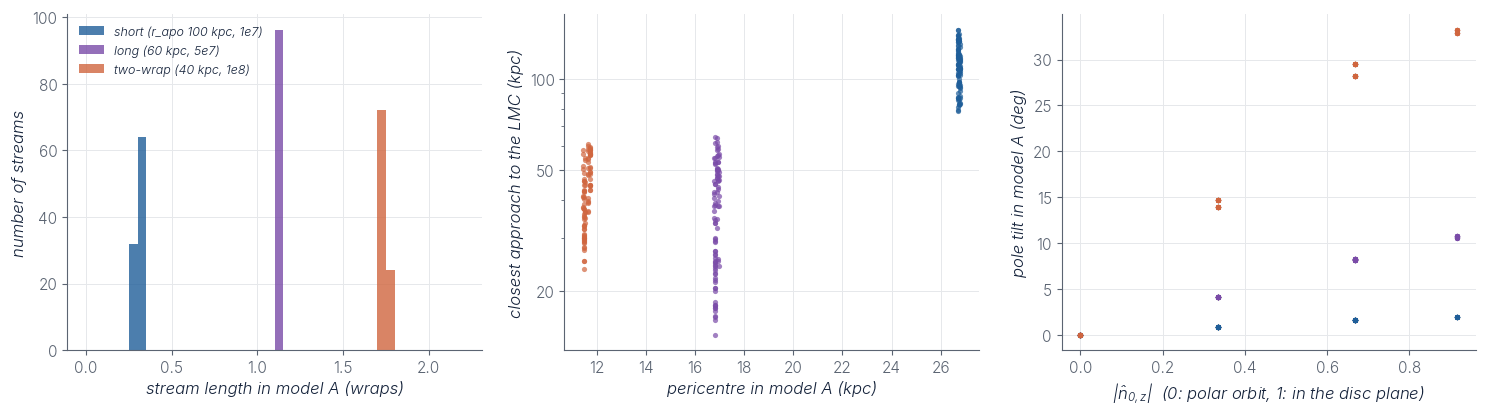

Figura: hito4_catalogo.png 
Milestone 4, the catalogue. Left: stream lengths in the isolated MW (model A) for the three families. Centre: pericentre against the closest approach of the progenitor to the LMC (model D). Right: tilt of the mean orbital pole from the initial pole in model A, against the z component of the initial pole: the disc makes non-polar orbital planes precess, which sets the floor of the tilt metrics.


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
COLF = {"corta": E.COLOR_MODELO["B"], "larga": E.COLOR_MODELO["D"], "doble": E.COLOR_MODELO["C"]}
NOMF = {"corta": "short (r_apo 100 kpc, 1e7)", "larga": "long (60 kpc, 5e7)", "doble": "two-wrap (40 kpc, 1e8)"}
for fam in ("corta", "larga", "doble"):
    s = DF["familia"] == fam
    ax[0].hist(DF.loc[s, "longitud_vueltas_A"], bins=np.linspace(0, 2.2, 45), color=COLF[fam], alpha=0.8, label=NOMF[fam])
    ax[1].scatter(DF.loc[s, "peri_kpc"], DF.loc[s, "dmin_lmc_kpc"], s=14, color=COLF[fam], alpha=0.7, lw=0)
ax[0].set_xlabel("stream length in model A (wraps)"); ax[0].set_ylabel("number of streams"); ax[0].legend(fontsize=9)
ax[1].set_xlabel("pericentre in model A (kpc)"); ax[1].set_ylabel("closest approach to the LMC (kpc)"); ax[1].set_yscale("log")
z = np.abs(np.array(DF["polo"].tolist())[:, 2])
for fam in ("corta", "larga", "doble"):
    s = (DF["familia"] == fam).to_numpy()
    ax[2].scatter(z[s], DF.loc[s, "tilt_polo_deg_todo_A"], s=14, color=COLF[fam], alpha=0.7, lw=0)
ax[2].set_xlabel(r"$|\hat{n}_{0,z}|$  (0: polar orbit, 1: in the disc plane)")
ax[2].set_ylabel("pole tilt in model A (deg)")
for A in ax: E.grilla(A)
fig.tight_layout()
PIE = 'Milestone 4, the catalogue. Left: stream lengths in the isolated MW (model A) for the three families. Centre: pericentre against the closest approach of the progenitor to the LMC (model D). Right: tilt of the mean orbital pole from the initial pole in model A, against the z component of the initial pole: the disc makes non-polar orbital planes precess, which sets the floor of the tilt metrics.'
E.guardar(fig, os.path.join(SAL, 'hito4_catalogo.png'), PIE, FUENTE, pdf=True)
plt.show()
print("Figura:", 'hito4_catalogo.png', "\n" + PIE)

In [9]:
from p3streams import resultados as R2
ruta = R2.exportar(DF.drop(columns=["sentido_lmc"]), "hito4_catalogo_con_geometria", SAL)
print("Catalogo exportado:", ruta)

Catalogo exportado: /content/drive/MyDrive/lapis26_p3/salidas/04_hito4_20261028_134324/hito4_catalogo_con_geometria.csv
